In [1]:
#Updated and Adapted from Lab 1 Calculations
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import glob

In [2]:
def correct_encoding(measured_image):
    return measured_image / 16 +1

In [3]:
#Creation of Difference Image
with fits.open('Lab2/bias/bias-0001.fit') as hdul_bias1, fits.open('Lab2/bias/bias-0002.fit') as hdul_bias2:
    
    bias1_data = hdul_bias1[0].data
    bias2_data = hdul_bias2[0].data
    
    header = hdul_bias1[0].header

diff_data = bias1_data - bias2_data

hdu_diff = fits.PrimaryHDU(data=diff_data, header=header)
hdu_diff.writeto('difference_image.fits', overwrite=True)


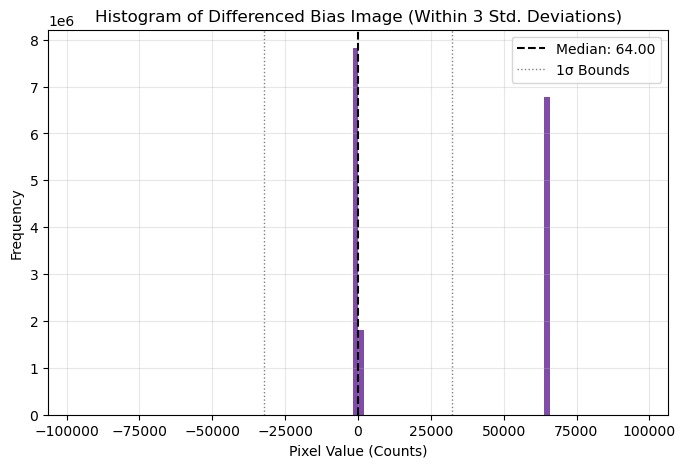

In [4]:
#Plotting of Difference Histogram
with fits.open('difference_image.fits') as hdul:
    diff_data = hdul[0].data

flat_data = diff_data.flatten()
flat_data = flat_data[~np.isnan(flat_data)]

median = np.median(flat_data)
std_dev = np.std(flat_data)

xmin = median - 3 * std_dev
xmax = median + 3 * std_dev

plt.figure(figsize=(8, 5))
plt.hist(flat_data, bins=100, range=(xmin, xmax), color='indigo', histtype='stepfilled', alpha=0.7)

plt.axvline(median, color='black', linestyle='dashed', linewidth=1.5, label=f'Median: {median:.2f}')
plt.axvline(median - std_dev, color='gray', linestyle='dotted', linewidth=1, label=f'1σ Bounds')
plt.axvline(median + std_dev, color='gray', linestyle='dotted', linewidth=1)

plt.title('Histogram of Differenced Bias Image (Within 3 Std. Deviations)')
plt.xlabel('Pixel Value (Counts)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


In [5]:
#Calculation of Read Noise

sigma_diff = np.std(diff_data)
read_noise = sigma_diff / np.sqrt(2)

In [6]:
sigma_diff

np.float64(32232.81712955645)

In [7]:
read_noise

np.float64(22792.043569055273)

In [8]:
#Bias Image Calculations
bias_files = glob.glob('Lab2/bias/*.fit')

#Correcting each bias image
corrected_array = []
for bias_path in bias_files:
    with fits.open(bias_path, mode='update') as foo:
        measured_image = foo[0].data

        if measured_image is not None:
            corrected_image = correct_encoding(measured_image)
            foo.data = corrected_image
            corrected_array.append(foo.data)

Text(0.5, 1.0, 'Average Bias Image: QHY 163M CMOS')

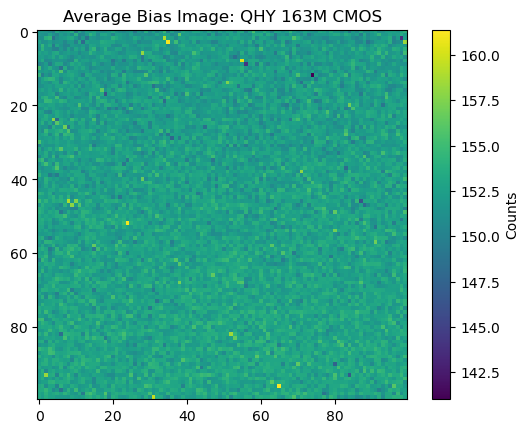

In [9]:
#Taking the average/median of the average of the now corrected images
bias_array = np.array(corrected_array)
bias_avg = np.mean(bias_array, axis=0)
bias_avg_median = np.median(bias_avg)

plt.imshow(bias_avg[0:100, 0:100])
plt.colorbar(label ='Counts')
plt.title('Average Bias Image: QHY 163M CMOS')

Text(0.5, 1.0, 'Average Bias Image: QHY 163M CMOS')

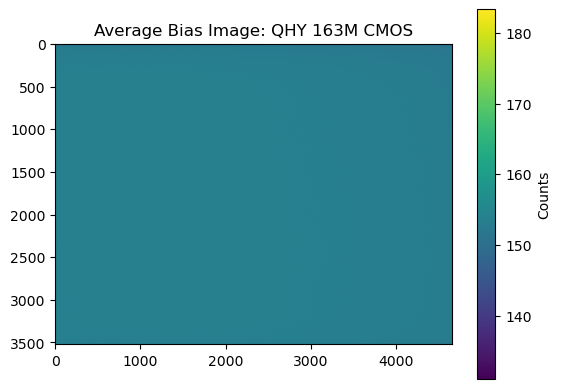

In [10]:
plt.imshow(bias_avg)
plt.colorbar(label='Counts')
plt.title('Average Bias Image: QHY 163M CMOS')


In [11]:
bias_avg_median

np.float64(153.7)

Text(0.5, 1.0, 'Average Dark Image: QHY 163M CMOS')

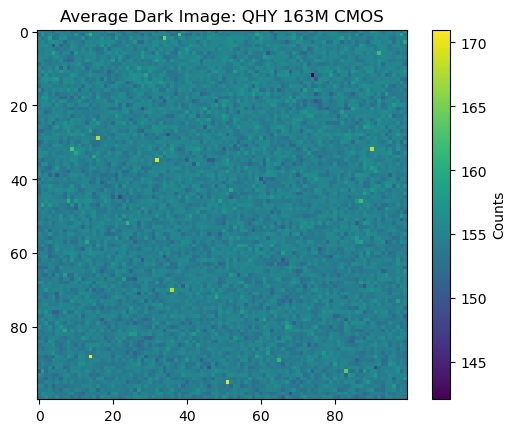

In [12]:
#Dark Image Calculations(Time 1)
dark1_files = glob.glob('Lab2/Darks10/*.fit')

#Correcting each dark image
corrected_array2 = []
for dark_path in dark1_files:
    with fits.open(dark_path, mode='update') as foo:
        measured_image = foo[0].data

        if measured_image is not None:
            corrected_image = correct_encoding(measured_image)
            foo.data = corrected_image
            corrected_array2.append(foo.data)

#Taking the average/median of the average of the now corrected images
dark1_array = np.array(corrected_array2)
dark1_avg = np.mean(dark1_array, axis=0)
dark1_avg_median = np.median(dark1_avg)

plt.imshow(dark1_avg[0:100, 0:100])
plt.colorbar(label ='Counts')
plt.title('Average Dark Image: QHY 163M CMOS')

Text(0.5, 1.0, 'Average Dark Image: QHY 163M CMOS')

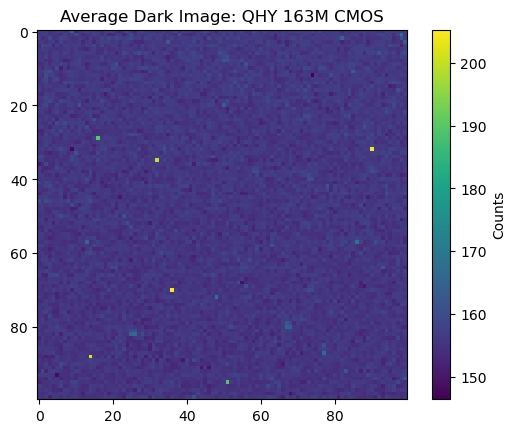

In [13]:
#Dark Image Calculations(Time 2)
dark2_files = glob.glob('Lab2/Darks30/*.fit')

#Correcting each dark image
corrected_array3 = []
for dark_path in dark2_files:
    with fits.open(dark_path, mode='update') as foo:
        measured_image = foo[0].data

        if measured_image is not None:
            corrected_image = correct_encoding(measured_image)
            foo.data = corrected_image
            corrected_array3.append(foo.data)

#Taking the average/median of the average of the now corrected images
dark2_array = np.array(corrected_array3)
dark2_avg = np.mean(dark2_array, axis=0)
dark2_avg_median = np.median(dark2_avg)

plt.imshow(dark2_avg[0:100, 0:100])
plt.colorbar(label ='Counts')
plt.title('Average Dark Image: QHY 163M CMOS')

In [14]:
#Dark Image Calculations(Time 3)
#dark3_files = glob.glob('Lab1/dark_time-3/*.fit')

#Correcting each dark image
#corrected_array4 = []
#for dark_path in dark3_files:
    #with fits.open(dark_path, mode='update') as foo:
        #measured_image = foo[0].data

        #if measured_image is not None:
            #corrected_image = correct_encoding(measured_image)
            #foo.data = corrected_image
            #corrected_array4.append(foo.data)

#Taking the average/median of the average of the now corrected images
#dark3_array = np.array(corrected_array4)
#dark3_avg = np.mean(dark3_array, axis=0)
#dark3_avg_median = np.median(dark3_avg)

#plt.imshow(dark3_avg[0:100, 0:100])
#plt.colorbar(label ='Counts')
#plt.title('Average Dark Image: QHY 163M CMOS')

Text(0.5, 1.0, 'Average Normalized Twilight Flat: QHY 163M CMOS')

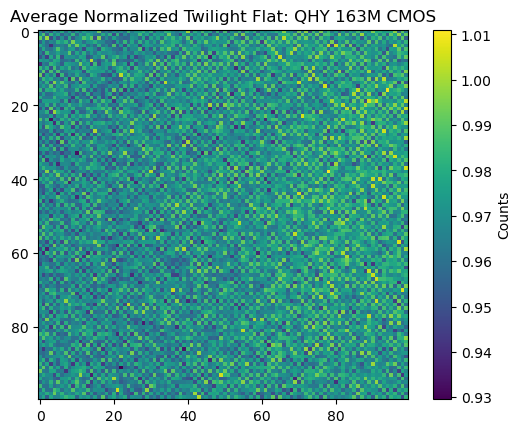

In [15]:
#Twilight Flat Calculations(
flat_files = glob.glob('Lab2/select_flats/*.fit')

#Correcting and normalizing each flat image
normal_stack = []
for flat_path in flat_files:
    with fits.open(flat_path, mode='update') as foo:
        measured_image = foo[0].data

        if measured_image is not None:
            corrected_image = correct_encoding(measured_image)
            z_i = corrected_image - bias_avg
            z_i_med = np.median(z_i)
            z_i_normal = z_i / z_i_med
            normal_stack.append(z_i_normal)

#Combining all corrected and normalized flats
final_normal_twi = np.median(normal_stack, axis=0)

plt.imshow(final_normal_twi[0:100, 0:100])
plt.colorbar(label ='Counts')
plt.title('Average Normalized Twilight Flat: QHY 163M CMOS')

In [16]:
#Creation of Calibrated Science Image For Loop 1 (PiPeg 1)
PiPeg_files = glob.glob('Lab2/PiPeg/*.fit')

for index, PiPeg_path in enumerate(PiPeg_files):
    with fits.open(PiPeg_path) as hdul:
        S_i = hdul[0].data.astype(float)
        
        d = dark1_avg
        
        b = bias_avg
        
        flat = final_normal_twi

    calibrated_data_1 = (S_i - d - b) / flat
    output_name = f"PiPeg_corrected_{index}.fits"
    hdu = fits.PrimaryHDU(calibrated_data_1)
    hdu.writeto(output_name, overwrite=True)


In [17]:
#Load a corrected file and view corrected image to check process
with fits.open('PiPeg_corrected_0.fits') as hdul:
    data = hdul[0].data.astype(float)

<function matplotlib.pyplot.show(close=None, block=None)>

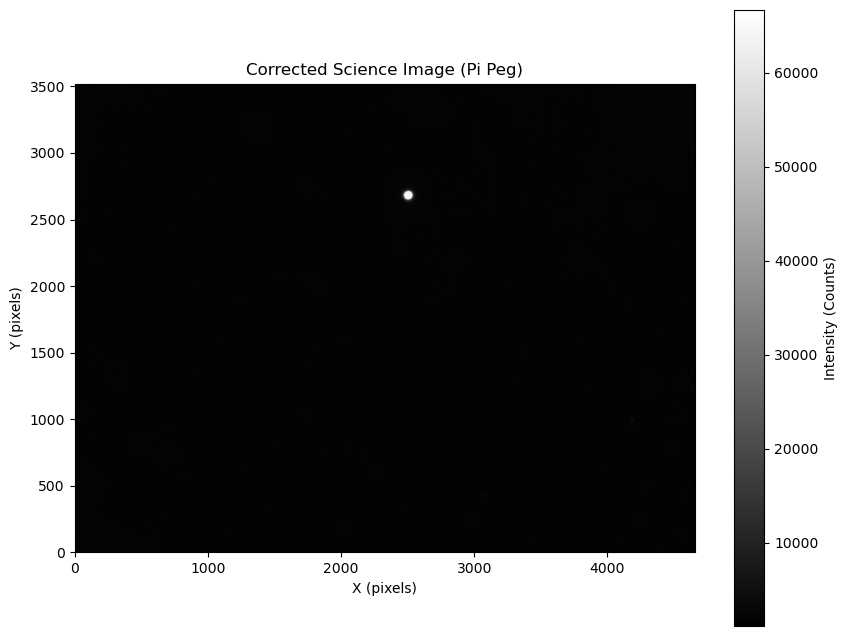

In [18]:
plt.figure(figsize=(10,8))
img = plt.imshow(data, cmap = 'grey', origin='lower')
plt.xlabel('X (pixels)')
plt.ylabel('Y (pixels)')
plt.colorbar(img, label = 'Intensity (Counts)')
plt.title('Corrected Science Image (Pi Peg)')

plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

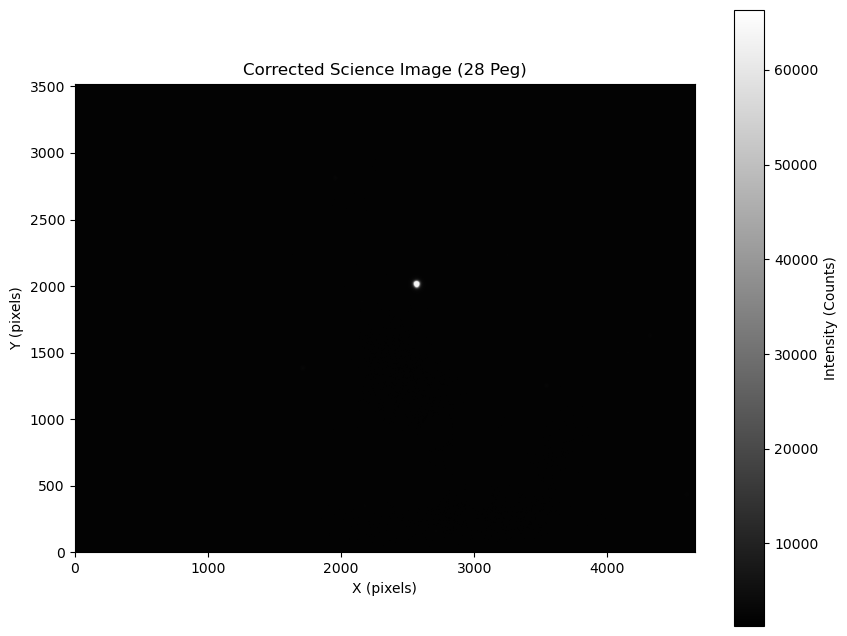

In [19]:
#Creation of Calibrated Science Image For Loop 2 (28 Peg 1)
TEPeg_files = glob.glob('Lab2/TEPeg/*.fit')

for index, TEPeg_path in enumerate(TEPeg_files):
    with fits.open(TEPeg_path) as hdul:
        S_i = hdul[0].data.astype(float)
        
        d = dark1_avg
        
        b = bias_avg
        
        flat = final_normal_twi

    calibrated_data_2 = (S_i - d - b) / flat
    output_name = f"28Peg_corrected_{index}.fits"
    hdu = fits.PrimaryHDU(calibrated_data_2)
    hdu.writeto(output_name, overwrite=True)


with fits.open('28Peg_corrected_0.fits') as hdul:
    data = hdul[0].data.astype(float)

plt.figure(figsize=(10,8))
img = plt.imshow(data, cmap = 'grey', origin='lower')
plt.xlabel('X (pixels)')
plt.ylabel('Y (pixels)')
plt.colorbar(img, label = 'Intensity (Counts)')
plt.title('Corrected Science Image (28 Peg)')

plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

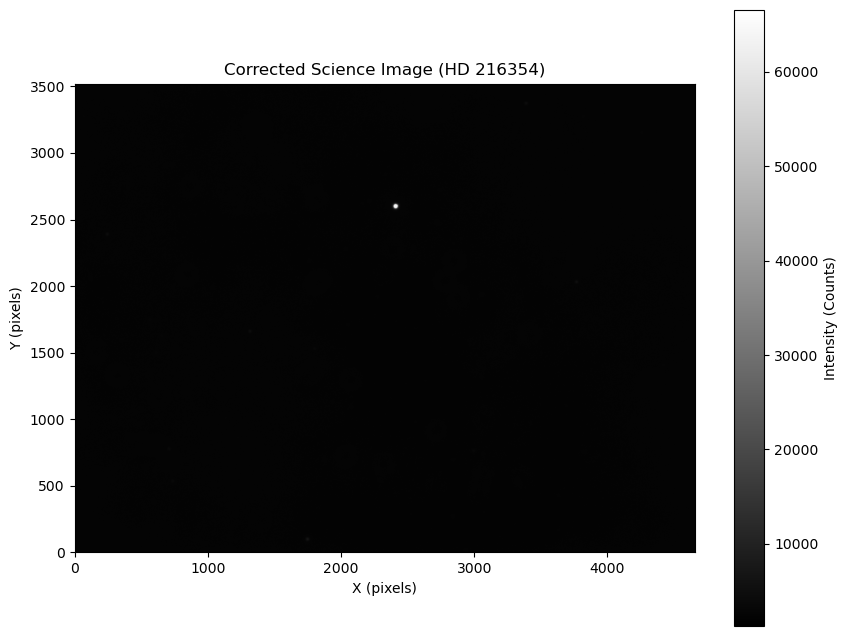

In [20]:
#Creation of Calibrated Science Image For Loop 3 (HD216 1)
HD216_files = glob.glob('Lab2/HD216/*.fit')

for index, HD216_path in enumerate(HD216_files):
    with fits.open(HD216_path) as hdul:
        S_i = hdul[0].data.astype(float)
        
        d = dark2_avg
        
        b = bias_avg
        
        flat = final_normal_twi

    calibrated_data_2 = (S_i - d - b) / flat
    output_name = f"HD216_corrected_{index}.fits"
    hdu = fits.PrimaryHDU(calibrated_data_2)
    hdu.writeto(output_name, overwrite=True)


with fits.open('HD216_corrected_0.fits') as hdul:
    data = hdul[0].data.astype(float)

plt.figure(figsize=(10,8))
img = plt.imshow(data, cmap = 'grey', origin='lower')
plt.xlabel('X (pixels)')
plt.ylabel('Y (pixels)')
plt.colorbar(img, label = 'Intensity (Counts)')
plt.title('Corrected Science Image (HD 216354)')

plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

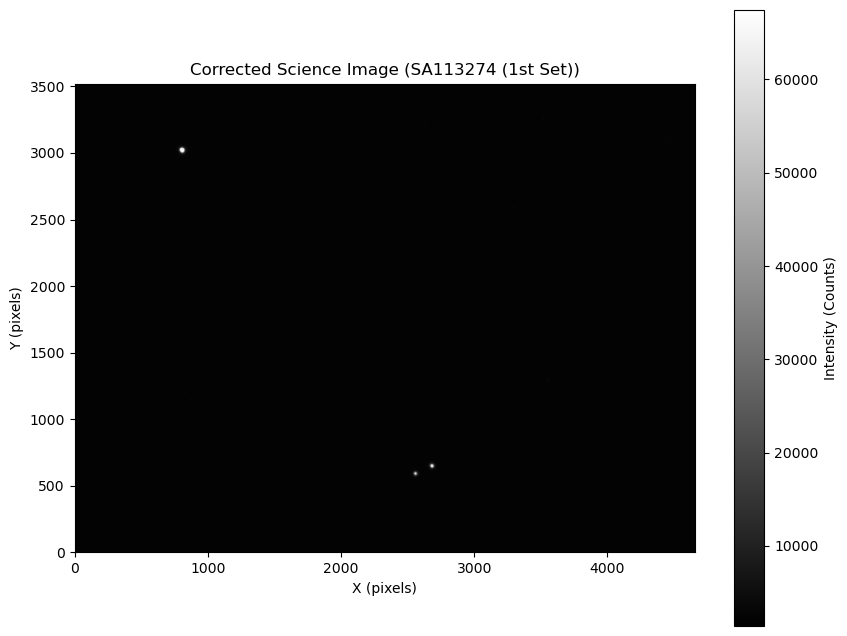

In [25]:
#Creation of Calibrated Calibrator Image For Loop 1 (SA113 (1st))
SA113_1st_files = glob.glob('Lab2/SA113-1st/*.fit')

for index, SA113_1st_path in enumerate(SA113_1st_files):
    with fits.open(SA113_1st_path) as hdul:
        S_i = hdul[0].data.astype(float)
        
        d = dark1_avg
        
        b = bias_avg
        
        flat = final_normal_twi

    calibrated_data_2 = (S_i - d - b) / flat
    output_name = f"SA113_1st_corrected_{index}.fits"
    hdu = fits.PrimaryHDU(calibrated_data_2)
    hdu.writeto(output_name, overwrite=True)


with fits.open('SA113_1st_corrected_0.fits') as hdul:
    data = hdul[0].data.astype(float)

plt.figure(figsize=(10,8))
img = plt.imshow(data, cmap = 'grey', origin='lower')
plt.xlabel('X (pixels)')
plt.ylabel('Y (pixels)')
plt.colorbar(img, label = 'Intensity (Counts)')
plt.title('Corrected Science Image (SA113274 (1st Set))')

plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

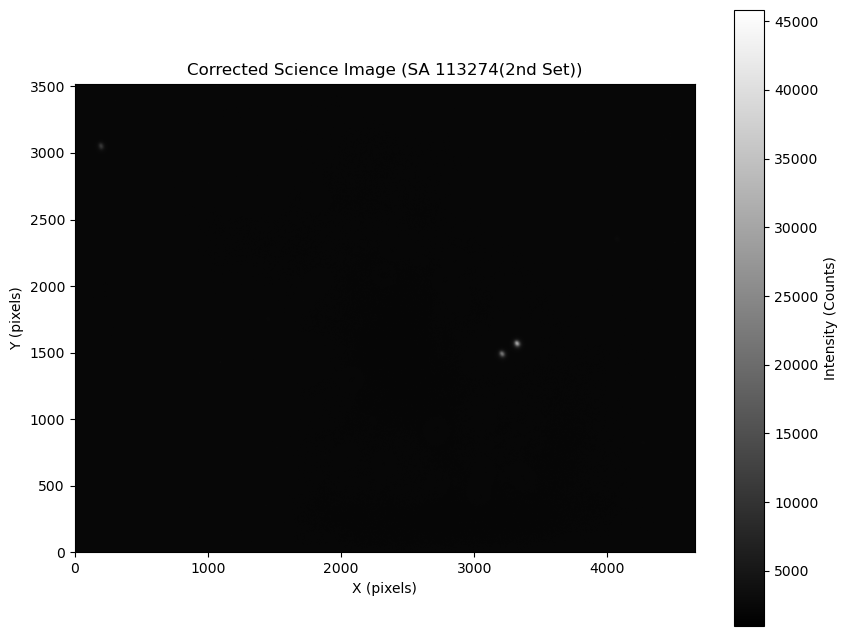

In [27]:
#Creation of Calibrated Calibrator Image For Loop 2 (SA113 (2nd))
SA113_2nd_files = glob.glob('Lab2/SA113-2nd/*.fit')

for index, SA113_2nd_path in enumerate(SA113_2nd_files):
    with fits.open(SA113_2nd_path) as hdul:
        S_i = hdul[0].data.astype(float)
        
        d = dark1_avg
        
        b = bias_avg
        
        flat = final_normal_twi

    calibrated_data_2 = (S_i - d - b) / flat
    output_name = f"SA113_2nd_corrected_{index}.fits"
    hdu = fits.PrimaryHDU(calibrated_data_2)
    hdu.writeto(output_name, overwrite=True)


with fits.open('SA113_2nd_corrected_0.fits') as hdul:
    data = hdul[0].data.astype(float)

plt.figure(figsize=(10,8))
img = plt.imshow(data, cmap = 'grey', origin='lower')
plt.xlabel('X (pixels)')
plt.ylabel('Y (pixels)')
plt.colorbar(img, label = 'Intensity (Counts)')
plt.title('Corrected Science Image (SA 113274(2nd Set))')

plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

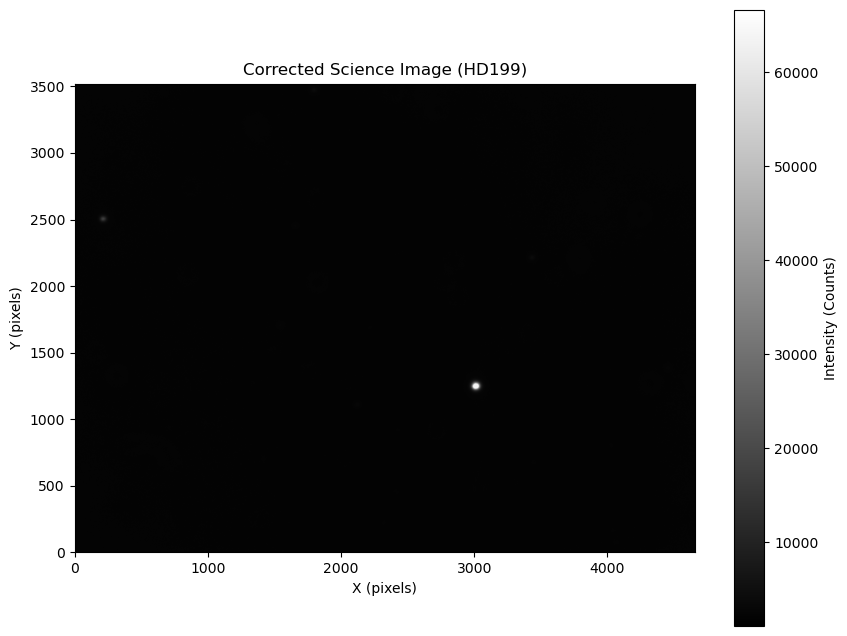

In [28]:
#Creation of Calibrated Calibrator Image For loop 3 (HD199)
HD199_files = glob.glob('Lab2/HD199/*.fit')

for index, HD199_path in enumerate(HD199_files):
    with fits.open(HD199_path) as hdul:
        S_i = hdul[0].data.astype(float)
        
        d = dark2_avg
        
        b = bias_avg
        
        flat = final_normal_twi

    calibrated_data_2 = (S_i - d - b) / flat
    output_name = f"HD199_corrected_{index}.fits"
    hdu = fits.PrimaryHDU(calibrated_data_2)
    hdu.writeto(output_name, overwrite=True)


with fits.open('HD199_corrected_0.fits') as hdul:
    data = hdul[0].data.astype(float)

plt.figure(figsize=(10,8))
img = plt.imshow(data, cmap = 'grey', origin='lower')
plt.xlabel('X (pixels)')
plt.ylabel('Y (pixels)')
plt.colorbar(img, label = 'Intensity (Counts)')
plt.title('Corrected Science Image (HD199)')

plt.show

In [29]:
#Start of CCD Gain Procedure
from astropy.io import fits

def load_fits_file(file_path):
    """Loads a FITS file containing a single dataset.
    """
    with fits.open(file_path) as hdul:
        hdu = hdul[0] if hdul[0].data is not None else hdul[1]
        return hdu.data.copy(), hdu.header.copy()

In [32]:
first_twilight = "Lab2/select_flats/twilightFlats_oct15-0001.fit"
image_data, header_info = load_fits_file(first_twilight)
np.mean(image_data)

np.float64(31821.92489623398)

In [33]:
last_twilight = "Lab2/twilightFlats_oct15-0100.fit"
image_data, header_info = load_fits_file(last_twilight)
np.mean(image_data)

np.float64(3366.7724699532246)

In [34]:
#Chosen Levels
#30000
#25000
#20000
#15000
#10000
#7500
#5000
#3000

In [40]:
#Create bias corrected flats
flat_files = glob.glob('Lab2/select_flats/*.fit')
for index, flat_path in enumerate(flat_files):
    with fits.open(flat_path,) as foo:
        measured_image = foo[0].data

        if measured_image is not None:
            corrected_image = correct_encoding(measured_image)
        output_name = f"twilightflat__oct15_{index}.fits"
    hdu = fits.PrimaryHDU(corrected_image)
    hdu.writeto(output_name, overwrite=True)

In [ ]:
#Level 1: 30000 Counts
twi_1st_lvl1 = "Lab2/corrected_flats/twilightflat_oct15_0.fit"
image_data_1, header_info_1 = load_fits_file(twi_1st_lvl1)
plt.imshow(image_data_1[0:75, 0:75])


def match_mean_signals(image_a, image_b, subarray_slices=None):
    """
    Measures the mean signal in subarrays of two images, calculates their ratio,
    and scales image B to match the mean signal level of image A.
    
    Parameters:
    -----------
    image_a : ndarray
        The reference image (Image A).
    image_b : ndarray
        The image to be scaled (Image B).
    subarray_slices : tuple of slice objects, optional
        The specific pixel coordinates defining the subarrays (FA and FB).
        Format: (slice(y_start, y_end), slice(x_start, x_end)).
        If None, the mean is calculated over the entire image.
        
    Returns:
    --------
    image_b_scaled : ndarray
        Image B scaled to match the mean signal level of Image A.
    r : float
        The calculated ratio (FA / FB).
    """
    if subarray_slices is None:
        sub_a = image_a
        sub_b = image_b
    else:
        sub_a = image_a[subarray_slices]
        sub_b = image_b[subarray_slices]
        
    FA = np.mean(sub_a)
    FB = np.mean(sub_b)
        
    r = FA / FB
    image_b_scaled = image_b * r
    
    return image_b_scaled, r
